In [ ]:
!pip install -q rdkit xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 56.8 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import pandas as pd, numpy as np
from pathlib import Path

SEED = 42
BASE = Path("/content/drive/MyDrive/kpneu_project")
df = pd.read_csv(BASE / "data/splits/split_v1.csv").reset_index(drop=True)
print("Shape:", df.shape, "(expected 14208 rows)")

# Leave as None to auto-detect; type the exact names here if detection fails
SMILES_COL = None
LABEL_COL  = None

if SMILES_COL is None:
    cands = [c for c in df.columns if "smiles" in c.lower()]
    assert cands, f"No SMILES column. Columns: {df.columns.tolist()}"
    pref = [c for c in cands if any(k in c.lower() for k in ("std", "standard", "canonical", "clean"))]
    SMILES_COL = (pref or cands)[0]

if LABEL_COL is None:
    def is_binary(s):
        v = set(s.dropna().unique().tolist())
        return len(v) == 2 and v <= {0, 1, True, False}
    named = [c for c in df.columns if any(k in c.lower() for k in ("active", "label")) and is_binary(df[c])]
    anybin = [c for c in df.columns if is_binary(df[c])]
    pool = named or anybin
    assert pool, f"No 0/1 label column. Columns: {df.columns.tolist()}"
    LABEL_COL = pool[0]

df[LABEL_COL] = df[LABEL_COL].astype(int)
print(f"SMILES_COL = '{SMILES_COL}' | LABEL_COL = '{LABEL_COL}'")
print("Active fraction:", round(df[LABEL_COL].mean(), 3), "(expected about 0.418)")
print(df["split_scaffold"].value_counts().to_dict())

Mounted at /content/drive
Shape: (14208, 29) (expected 14208 rows)
SMILES_COL = 'can_smiles' | LABEL_COL = 'active'
Active fraction: 0.418 (expected about 0.418)
{'train': 11366, 'test': 1422, 'val': 1420}


In [ ]:
from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator
RDLogger.DisableLog("rdApp.*")

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
X = np.array([gen.GetFingerprintAsNumPy(Chem.MolFromSmiles(s)) for s in df[SMILES_COL]],
             dtype=np.uint8)
y = df[LABEL_COL].values
print("X:", X.shape, "| y:", y.shape)

feat_dir = BASE / "data/features"
feat_dir.mkdir(parents=True, exist_ok=True)
np.save(feat_dir / "morgan_r2_2048_v1.npy", X)
print("Saved features to", feat_dir)

X: (14208, 2048) | y: (14208,)
Saved features to /content/drive/MyDrive/kpneu_project/data/features


In [ ]:
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, matthews_corrcoef, brier_score_loss

def make_models():
    return {
        "RF": RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=SEED),
        "LogReg": LogisticRegression(C=1.0, max_iter=2000),
        "XGBoost": XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=6,
                                 subsample=0.8, colsample_bytree=0.5,
                                 eval_metric="logloss", random_state=SEED, n_jobs=-1),
    }

def ece(y_true, p, bins=10):
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(p, edges[1:-1]), 0, bins - 1)
    total = 0.0
    for b in range(bins):
        m = idx == b
        if m.any():
            total += m.mean() * abs(y_true[m].mean() - p[m].mean())
    return total

def metrics(y_true, p, thr=0.5):
    return {
        "roc_auc": roc_auc_score(y_true, p),
        "pr_auc": average_precision_score(y_true, p),
        "mcc": matthews_corrcoef(y_true, (p >= thr).astype(int)),
        "brier": brier_score_loss(y_true, p),
        "ece": ece(y_true, p),
    }

print("Baselines to beat: ROC-AUC 0.5, PR-AUC =", round(y.mean(), 3), "(the active fraction), MCC 0")

Baselines to beat: ROC-AUC 0.5, PR-AUC = 0.418 (the active fraction), MCC 0


In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

# Reloading the CSV turns empty scaffolds into NaN, so give acyclic molecules a proper name
df["scaffold"] = df["scaffold"].fillna("ACYCLIC").astype(str)
print("Acyclic molecules:", (df["scaffold"] == "ACYCLIC").sum())

tr = (df["split_scaffold"] == "train").values
Xtr, ytr, gtr = X[tr], y[tr], df.loc[tr, "scaffold"].values

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name in make_models():
    for fold, (a, b) in enumerate(cv.split(Xtr, ytr, gtr)):
        # sanity check: no scaffold shared between the training and held-out parts
        assert not (set(gtr[a]) & set(gtr[b])), "Scaffold leak between CV folds"
        m = make_models()[name]
        m.fit(Xtr[a], ytr[a])
        r = metrics(ytr[b], m.predict_proba(Xtr[b])[:, 1])
        r.update(model=name, fold=fold)
        rows.append(r)
    print("done:", name)

cvres = pd.DataFrame(rows)
summary = cvres.groupby("model")[["roc_auc", "pr_auc", "mcc", "brier", "ece"]].agg(["mean", "std"]).round(3)
display(summary)

(BASE / "results").mkdir(exist_ok=True)
cvres.to_csv(BASE / "results/day5_cv_scaffold_train.csv", index=False)

Acyclic molecules: 303
done: RF
done: LogReg
done: XGBoost


roc_auc        pr_auc           mcc         brier           ece       
           mean    std   mean    std   mean    std   mean    std   mean    std
model                                                                         
LogReg    0.825  0.013  0.784  0.022  0.495  0.033  0.178  0.008  0.103  0.008
RF        0.872  0.012  0.851  0.016  0.590  0.019  0.141  0.006  0.030  0.007
XGBoost   0.849  0.016  0.835  0.018  0.562  0.031  0.151  0.009  0.023  0.004

In [ ]:
rows, probs = [], {}
for split_col in ["split_scaffold", "split_random"]:
    trm = (df[split_col] == "train").values
    for name in make_models():
        m = make_models()[name]
        m.fit(X[trm], y[trm])
        for part in ["val", "test"]:
            pm = (df[split_col] == part).values
            p = m.predict_proba(X[pm])[:, 1]
            r = metrics(y[pm], p)
            r.update(split=split_col.replace("split_", ""), model=name, eval_set=part)
            rows.append(r)
            if split_col == "split_scaffold":
                probs[(name, part)] = (y[pm], p)
        print("done:", split_col, name)

res = pd.DataFrame(rows)[["split", "model", "eval_set", "roc_auc", "pr_auc", "mcc", "brier", "ece"]]
display(res.round(3))
res.to_csv(BASE / "results/day5_baseline_metrics.csv", index=False)

done: split_scaffold RF
done: split_scaffold LogReg
done: split_scaffold XGBoost
done: split_random RF
done: split_random LogReg
done: split_random XGBoost


,split,model,eval_set,roc_auc,pr_auc,mcc,brier,ece
0,scaffold,RF,val,0.898,0.864,0.629,0.117,0.068
1,scaffold,RF,test,0.867,0.842,0.556,0.147,0.050
2,scaffold,LogReg,val,0.846,0.753,0.545,0.157,0.081
3,scaffold,LogReg,test,0.800,0.742,0.459,0.188,0.109
4,scaffold,XGBoost,val,0.896,0.848,0.662,0.124,0.067
5,scaffold,XGBoost,test,0.841,0.812,0.517,0.161,0.055
6,random,RF,val,0.919,0.903,0.693,0.108,0.024
7,random,RF,test,0.924,0.896,0.687,0.106,0.032
8,random,LogReg,val,0.884,0.853,0.609,0.135,0.049
9,random,LogReg,test,0.883,0.832,0.609,0.139,0.054


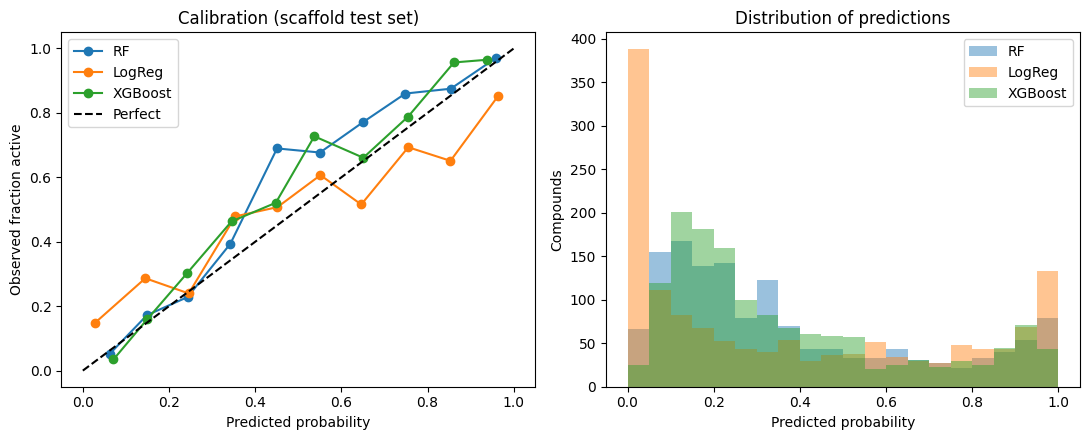

In [ ]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for name in make_models():
    yt, p = probs[(name, "test")]
    frac, mean_p = calibration_curve(yt, p, n_bins=10, strategy="uniform")
    ax[0].plot(mean_p, frac, marker="o", label=name)
    ax[1].hist(p, bins=20, range=(0, 1), alpha=0.45, label=name)
ax[0].plot([0, 1], [0, 1], "k--", label="Perfect")
ax[0].set_xlabel("Predicted probability"); ax[0].set_ylabel("Observed fraction active")
ax[0].set_title("Calibration (scaffold test set)"); ax[0].legend()
ax[1].set_xlabel("Predicted probability"); ax[1].set_ylabel("Compounds")
ax[1].set_title("Distribution of predictions"); ax[1].legend()
plt.tight_layout()

(BASE / "plots").mkdir(exist_ok=True)
plt.savefig(BASE / "plots/day5_calibration.png", dpi=200, bbox_inches="tight")
plt.show()